Ahmed Amer Alshehri 2230002008 9MA2

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [ ]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv("/content/drive/MyDrive/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

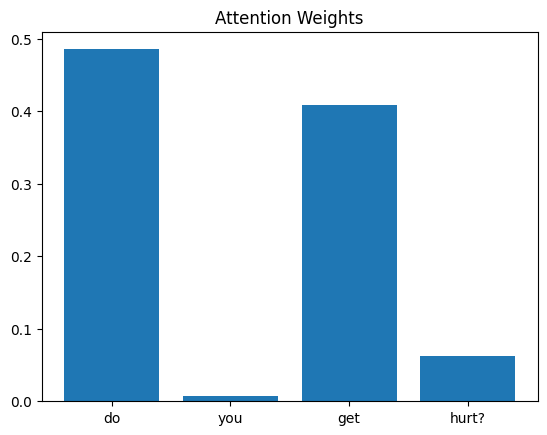

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


In [ ]:
# Helper used by Task 1 and Task 2
def get_attention(question_text):
    """Return the words, attention weights and prediction for one question of the dataset."""
    idx = df.index[df["question"] == question_text.lower()][0]   # row of the question
    ids = [i for i in X[idx].tolist() if i != 0]                 # remove the padding zeros
    words = [tokenizer.index_word[i] for i in ids]               # numbers -> words

    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])

    all_weights = weights[0]                                     # one weight per position (padding included)
    word_weights = all_weights[:len(words)].tolist()             # weights of the real words only
    padding_share = all_weights[len(words):].sum().item()        # attention that went to the padding
    predicted_id = prediction.argmax(1).item()
    return words, word_weights, padding_share, predicted_id, int(df["answer_id"][idx])


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

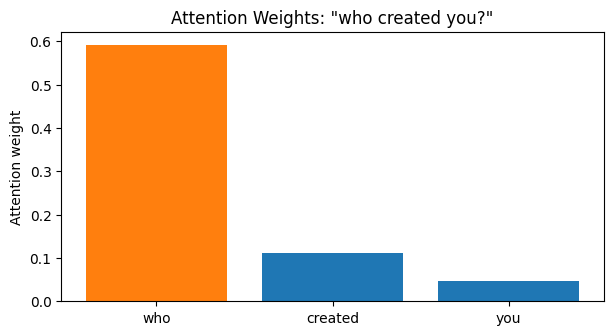

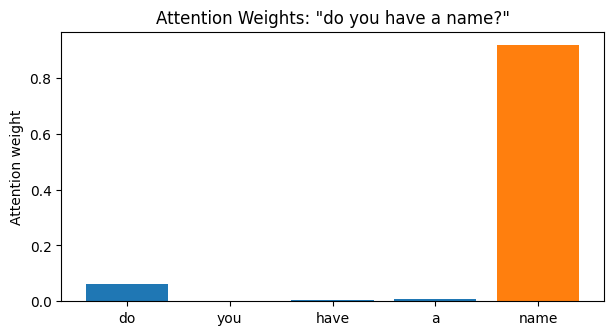

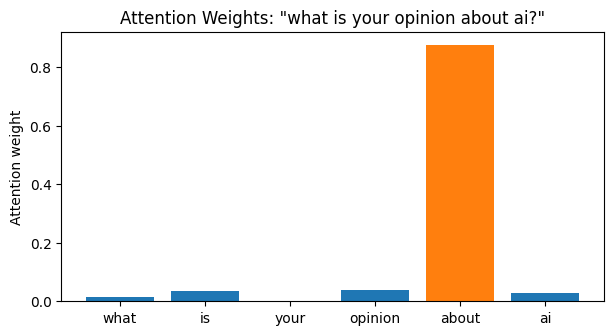

Uniform attention would give every position 0.091

"who created you?"
  highest attention: "who" = 0.592 (function word)
  attention on padding: 25.0% | model prediction correct: True
"do you have a name?"
  highest attention: "name" = 0.920 (content word)
  attention on padding: 0.4% | model prediction correct: False
"what is your opinion about ai?"
  highest attention: "about" = 0.878 (function word)
  attention on padding: 0.2% | model prediction correct: False


In [ ]:
# Task 1: attention weights for three different questions
questions = ["who created you?", "do you have a name?", "what is your opinion about ai?"]

# words that carry little meaning on their own (only used to label the top word below)
function_words = {"do", "you", "your", "are", "is", "a", "the", "what", "what's", "who", "how", "about", "i", "me", "have"}

summary = []
for q in questions:
    words, weights, padding_share, predicted_id, true_id = get_attention(q)
    top = weights.index(max(weights))                            # position of the highest weight

    colors = ["tab:orange" if i == top else "tab:blue" for i in range(len(words))]
    plt.figure(figsize=(7, 3.5))
    plt.bar(words, weights, color=colors)                        # orange bar = highest attention
    plt.title(f'Attention Weights: "{q}"')
    plt.ylabel("Attention weight")
    plt.show()

    summary.append((q, words[top], weights[top], padding_share, predicted_id == true_id))

print(f"Uniform attention would give every position {1 / X.shape[1]:.3f}\n")
for q, top_word, top_weight, padding_share, correct in summary:
    kind = "function word" if top_word in function_words else "content word"
    print(f'"{q}"')
    print(f'  highest attention: "{top_word}" = {top_weight:.3f} ({kind})')
    print(f'  attention on padding: {padding_share:.1%} | model prediction correct: {correct}')


**Answer (Task 1)**

The orange bar in each chart is the word with the highest attention weight. The summary printed under the charts names that word for every question and says whether it is a *content word* (it carries the meaning of the question) or a *function word* (*do*, *you*, *what*, ...).

- When the highest weight falls on a content word, the model is attending to the word that separates one answer group from the others, so the attention matches what a person would call important.
- When it falls on a function word such as *you* or *do*, the weight does not match human intuition. These words appear in almost every question of the dataset, so they say little about which answer is right. Attention is only a score learned to get the answer right, so nothing forces it to follow human ideas of importance.
- A top weight close to the uniform value printed above means the attention is almost flat. Some attention also goes to the padding positions, because this model does not mask them.

Overall, the attention weights are a useful hint about which words the model relied on, but they should be read together with the question and the model's accuracy, not treated as a perfect measure of importance.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

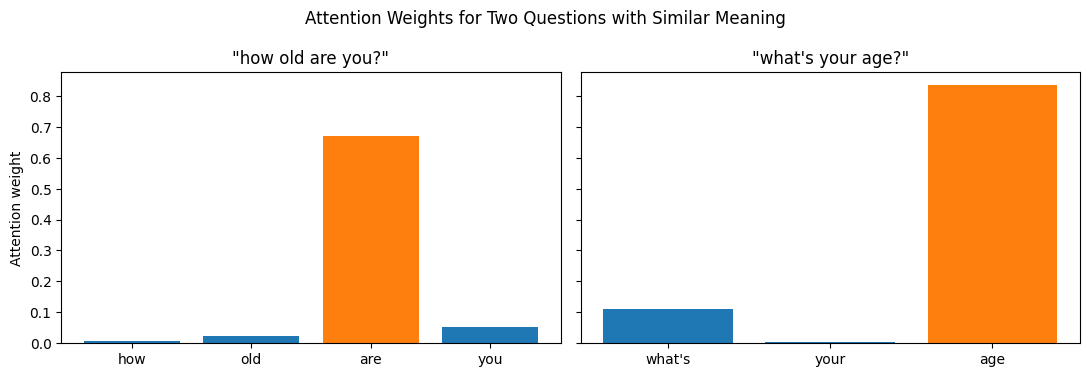

"how old are you?" -> highest attention: "are" (0.670)
"what's your age?" -> highest attention: "age" (0.834)
Words shared by the two questions: none
Same word with the highest attention: False
Same predicted answer: False | true answer group of both questions: 1 and 1


In [ ]:
# Task 2: two questions with similar meaning but different wording (both belong to answer group 1: age)
pair = ["how old are you?", "what's your age?"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
results = []
for q, ax in zip(pair, axes):
    words, weights, padding_share, predicted_id, true_id = get_attention(q)
    top = weights.index(max(weights))
    ax.bar(words, weights, color=["tab:orange" if i == top else "tab:blue" for i in range(len(words))])
    ax.set_title(f'"{q}"')
    results.append((words, weights, top, predicted_id, true_id))

axes[0].set_ylabel("Attention weight")
plt.suptitle("Attention Weights for Two Questions with Similar Meaning")
plt.tight_layout()
plt.show()

(words1, weights1, top1, pred1, true1), (words2, weights2, top2, pred2, true2) = results
print(f'"{pair[0]}" -> highest attention: "{words1[top1]}" ({weights1[top1]:.3f})')
print(f'"{pair[1]}" -> highest attention: "{words2[top2]}" ({weights2[top2]:.3f})')
print("Words shared by the two questions:", sorted(set(words1) & set(words2)) or "none")
print("Same word with the highest attention:", words1[top1] == words2[top2])
print("Same predicted answer:", pred1 == pred2, "| true answer group of both questions:", true1, "and", true2)


**Answer (Task 2)**

*how old are you?* and *what's your age?* are worded differently but belong to the same answer group. The printed lines list the highest-attention word of each question and the words the two questions share.

- The model does not look for a fixed set of words. Each weight is computed from the RNN hidden state at that position, which depends on the learned embedding and on the words before it. Questions with similar meaning but different wording can therefore put their highest weight on different words and still lead to the same answer.
- Matching top words are not required for the same prediction. What matters is that the weighted sum of the hidden states (the context vector) ends up close enough for the output layer to choose the same answer.

This suggests that attention is a learned relevance score that depends on the task and the context. It is not a rule that always highlights the same word, and it is not proof that the model understands the meaning.
